# Inference speed-ups, one request


## Intro (Human written!)


Hi! This is the notebook that was briefly introduced in the "LLM explained" session on 20.11.2026. \newline
It shows how using a KV cache can speed up inference. 

This notebook is made for educational purposes only, and it's mostly vibe-coded. If you see something strange in it, ask Claude OR drop me (*Margot Razumeyeva*) a message.

**Results** - main finding from running on an H100:
- with a short prompt, the KV cache changes nothing, because Python overhead sets the speed. 
- with an 8,192-token prompt, it is 7x faster.

**If you want to run it youself:** better to use NVIDIA GPU with 16 GB or more (T4 or newer). Details: "What GPU you need" in Setup.

Have fun! 

---

### Notebook map 

**Basic info**
- **What is being tested**: how much faster does an LLM answer one request with a KV cache? And with a static cache + `torch.compile`?
- **How**: each technique is built from scratch in a few lines of PyTorch, then switched on
  in `transformers`, and timed against a baseline.
- **Model**: Qwen3-4B, greedy decoding, one request at a time.
- **Stack**: PyTorch 2.14 with CUDA, `transformers` 5.19, `accelerate` 1.15.


**What is in:**

1. Setup: environment + settings + loading the model 
   * Install pinned packages, import, check for a CUDA GPU, pick bf16 or fp16.
   * Shared settings, the prompt in the chat template, timing, confidence intervals, result tables 
   *  Load Qwen3-4B, compute the speed limit 
2. KV cache. Reuse the keys and values of past tokens instead of recomputing them
3. Static cache + compile. Fix tensor shapes, so a decode step can be compiled and replayed as one CUDA graph 
4. Summary - All comparisons in one table and one chart


### Why decoding is slow - why do we need KV cashes?

An answer is made in two phases:
1. **Prefill**: one forward pass over the whole prompt.
2. **Decode**: one forward pass per new token. This is where most of the time goes.

Every decode step reads all model weights from GPU memory. Reading takes longer than
computing, so memory speed sets a limit:

    tokens per second <= memory bandwidth / weight size

Qwen3-4B weighs 8 GB: at most ~40 tok/s on a T4, ~416 tok/s on an H100.

Real speed is far below that limit. Every step runs the model's Python code and starts
~2,000 small GPU jobs (kernels). On a fast GPU, starting the jobs takes longer than running them: one H100 run reached only ~10% of the limit.



---

### How to run 


1. Run all Setup cells once, top to bottom. On Colab, restart the session after the
   install cell.
2. Run section 1, section 2, or both. The order does not matter.
3. Run the Summary.

<details>
<summary>Settings you can change</summary>

- **Model**: `Qwen/Qwen3-4B` by default. To use another model, set the
  `INFERENCE_TARGET_MODEL` environment variable with `%env` before the settings cell.
- **Tokens per run**: each `generate()` run makes 256 new tokens (`Config.n_new_tokens`).
- **Timed runs**: each configuration is timed 5 times, or 3 times for slow ones
  (`Config.n_repeat` and `Config.n_repeat_slow`).
- **Sweep lengths**: the output lengths, prompt lengths and tokens per call used in the
  sweeps are set in section 1 (`CACHE_SWEEP`, `CONTEXT_SWEEP`, `N_NEW_CONTEXT`).

</details>


### How to read the results

- **Speed** is tokens per second (tok/s). Each number is the median of 5 runs (3 for slow
  ones), after one warm-up run that is not counted.
- **Baseline**: each technique is compared with a baseline measured right before it.
- **95% confidence interval**: run-to-run noise. With 3-5 runs it is just the range from
  the slowest to the fastest run.
- **Same tokens**: identical output, up to 16-bit rounding.

### Limits

- One request at a time, greedy decoding. Serving many users at once is not covered.
- Results depend on the GPU, CPU and library versions. Compare numbers within one run,
  not across machines.

---

# 1. Setup (Claude-written context from here!)

### What GPU you need

- **An NVIDIA GPU** with CUDA. There is no CPU or Mac fallback. Only the first GPU is used.
- **T4 or newer.** The CUDA 13 build of PyTorch used here does not support V100 or older
  GPUs, and needs NVIDIA driver 580 or newer.
- **16 GB of GPU memory** or more. With 12 GB, remove 8192 from `CONTEXT_SWEEP`. With
  less, use a smaller model: `%env INFERENCE_TARGET_MODEL=Qwen/Qwen3-1.7B`.
- **Any of these works**: Colab T4 (free), L4, A10G, L40S, A100, H100, H200. A rented GPU
  is billed per hour: stop it when you are done.

The GPU changes what you will see. On a fast GPU (H100) the KV cache needs a long prompt
to show its gain; on a slower GPU (T4) it helps at every prompt length.

<details>
<summary>GPU details: memory, precision, what to expect per GPU</summary>

**Memory**

| What | GPU memory |
|---|---|
| Qwen3-4B weights, 16-bit | 8.0 GB |
| Sections 1 and 2, short prompt | ~8.1 GB peak (measured on an H100) |
| Section 1, 8,192-token sweep | ~10 GB (estimate) |
| CUDA context and allocator cache | ~0.5-1 GB extra, not counted by PyTorch |

Smaller models: `Qwen/Qwen3-1.7B` ~3.4 GB, `Qwen/Qwen3-0.6B` ~1.2 GB.

**Precision.** bf16 needs an Ampere GPU or newer (A100, A10G, L4, L40S, H100, H200,
RTX 30xx/40xx). A T4 runs in fp16: the same speed story, slightly different tokens.

**What to expect per GPU**

| GPU | Memory | Bandwidth | Speed limit, Qwen3-4B | Notes |
|---|---|---|---|---|
| T4 (Colab free) | 16 GB | 320 GB/s | ~40 tok/s | fp16. The KV cache helps even with a short prompt; the long-prompt sweep takes minutes |
| L4 | 24 GB | 300 GB/s | ~37 tok/s | Like a T4 for decoding |
| A10G | 24 GB | 600 GB/s | ~75 tok/s | |
| L40S | 48 GB | 864 GB/s | ~108 tok/s | |
| A100 | 40 or 80 GB | 1555-2000 GB/s | ~195-250 tok/s | |
| H100 | 80 GB | 3350 GB/s | ~416 tok/s | Overhead dominates: the KV cache needs a long prompt; section 2 gains most |
| H200 | 141 GB | 4800 GB/s | ~600 tok/s | Like an H100, even more so |

A GPU missing from `GPU_BANDWIDTH_GBS` gives a speed limit of `nan`: add its bandwidth
there.

**Other effects**
- A slow CPU means more overhead per step, so a smaller share of the speed limit.
- `torch.compile` (section 2) needs Triton support for the GPU. If it fails, the cell
  logs a warning and skips it.
- Attention uses FlashAttention kernels on Ampere and newer and another kernel on a T4:
  same results, different speed.
- AMD GPUs with a ROCm build of PyTorch might work, but are untested.

</details>

### Install and imports

You need a Python environment with PyTorch built for CUDA (see "What GPU you need"
above). The install cell adds the other packages at the versions this notebook
was written for.

- **Colab**: Runtime > Change runtime type > GPU. Run the install cell, restart the
  session (Runtime > Restart session), then continue from the imports cell. The restart
  is needed because Colab has an older `transformers` already loaded.
- **Your own GPU machine**: run the install cell once, restart the kernel, then continue
  from the imports cell.

When done, shut the GPU down: Colab: Runtime > Disconnect and delete runtime. Rented
machine: stop it in the provider's console, it is billed per hour.

In [2]:
# PyTorch with CUDA must already be installed. Versions this notebook was written for
%pip install -q "transformers==5.19.0" "accelerate==1.15.0" pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import gc
import logging
import math
import os
import sys
import time
from collections.abc import Callable
from dataclasses import dataclass
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    DynamicCache,
    GenerationConfig,
    PreTrainedModel,
    set_seed,
)

# Our messages go to the notebook output as plain text
log = logging.getLogger("inference")
log.setLevel(logging.INFO)
log.handlers[:] = [logging.StreamHandler(sys.stdout)]
log.propagate = False

### Libraries: who does what

| Library | Used for |
|---|---|
| `torch` (PyTorch) | Tensors, GPU memory, every math operation, attention (SDPA), `torch.compile` |
| `transformers` (Hugging Face) | The Qwen3 model code, loading weights, the tokenizer, the KV cache classes, `generate()` |
| `accelerate` | Used by `transformers` for `device_map`: loading the weights straight onto the GPU |
| `numpy`, `pandas`, `matplotlib` | Timing statistics, tables, charts |
| Python standard library | `time` (the clock), `functools.partial`, `gc`, `logging`, `dataclasses` |

Installed with them and used indirectly: `tokenizers` (the fast tokenizer, written in
Rust), `huggingface_hub` (downloads), `safetensors` (the weight files).

What happens when we call the model, from top to bottom:

    our code         the generation loop: one model call per new token
    transformers     the Qwen3 model code, in Python: 36 layers of attention + MLP
    torch            every line is a tensor operation; torch starts ("launches") a GPU
                     program, a kernel, for each one
    CUDA libraries   cuBLAS (matrix products), FlashAttention / cuDNN (attention),
                     Triton (kernels made by torch.compile, section 2)
    GPU              runs the kernels; its memory holds the weights and the KV cache

The KV cache is split between two libraries: `transformers` decides what to store and
when (the `DynamicCache` class), and `torch` holds the numbers as tensors in GPU memory.

### GPU

Stops if there is no CUDA GPU, and picks the 16-bit format: bf16 on Ampere and newer,
fp16 on older GPUs such as the T4.

In [4]:
assert torch.cuda.is_available(), "No GPU found. Colab: Runtime > Change runtime type"

DEVICE = torch.device("cuda", 0)
GPU_NAME = torch.cuda.get_device_name(DEVICE)
# bf16 needs compute capability 8.0+ (Ampere and newer); a T4 (7.5) uses fp16
IS_AMPERE_PLUS = torch.cuda.get_device_capability(DEVICE) >= (8, 0)
DTYPE = torch.bfloat16 if IS_AMPERE_PLUS else torch.float16
GB = 1e9

vram_gb = torch.cuda.get_device_properties(DEVICE).total_memory / GB
log.info(f"GPU:   {GPU_NAME}, {vram_gb:.0f} GB")
log.info(f"dtype: {DTYPE}")
log.info(f"torch {torch.__version__}, CUDA {torch.version.cuda}")

GPU:   NVIDIA H100 80GB HBM3, 85 GB
dtype: torch.bfloat16
torch 2.14.1+cu130, CUDA 13.0


## Settings and prompt

Settings shared by all sections are here; a setting used by one section only is in that
section. To try another target model, set an environment variable before this cell, e.g.
`%env INFERENCE_TARGET_MODEL=Qwen/Qwen3-1.7B`. Lower `n_repeat` for a faster but noisier
run.

The **open** prompt asks for an explanation in free text. The answer has little in
common with the prompt: the normal chat case.

In [5]:
@dataclass(frozen=True)
class Config:
    """Settings shared by all sections."""

    target_model: str = os.environ.get("INFERENCE_TARGET_MODEL", "Qwen/Qwen3-4B")
    seed: int = 42
    # Every generation produces exactly this many new tokens
    n_new_tokens: int = 256
    # Timed runs per configuration; fewer for slow ones (no cache, from-scratch loops)
    n_repeat: int = 5
    n_repeat_slow: int = 3


cfg = Config()
set_seed(cfg.seed)
RNG = np.random.default_rng(cfg.seed)  # for the confidence intervals
display(pd.Series(vars(cfg), name="value").to_frame())

,value
target_model,Qwen/Qwen3-4B
seed,42
n_new_tokens,256
n_repeat,5
n_repeat_slow,3


In [6]:
OPEN_PROMPT = (
    "Hey! Can you explain what Magic: The Gathering is? What are the basic rules of "
    "the game? Keep it simple and friendly, like you're telling a friend."
)

In [7]:
tokenizer = AutoTokenizer.from_pretrained(cfg.target_model)


def chat_input_ids(prompt: str) -> torch.Tensor:
    """Wrap a prompt in the model's chat template and turn it into token ids."""
    text = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,  # Qwen3: answer directly; other templates ignore it
    )
    ids = tokenizer(text, return_tensors="pt", add_special_tokens=False).input_ids
    return ids.to(DEVICE)


open_ids = chat_input_ids(OPEN_PROMPT)
log.info(f"open prompt: {open_ids.shape[1]} tokens")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

open prompt: 42 tokens


### How we measure

**Three timing traps, and how we avoid them**
- **The GPU works in the background.** A GPU call returns before the GPU has finished.
  We call `torch.cuda.synchronize()` before reading the clock, so we time the work, not just the start.
- **The first call is slow.** It pays one-time costs: loading GPU code, choosing
  algorithms, reserving memory, and waking an idle GPU. With `torch.compile` (section 3) it also compiles, which takes tens of seconds. So we run one warm-up call first and ignore its time. `free_memory()` releases memory, so the next call is slow again: one more reason to warm up.
- **Every run must do the same work.** We block the end-of-text token, so every run
  makes exactly `n_new_tokens` tokens.

**How many runs**
- 1 warm-up run (not timed), then 5 timed runs (`cfg.n_repeat`), or 3 for slow
  configurations (`cfg.n_repeat_slow`).
- We report the median: one odd run cannot move it much.
- `time_calls` needs a function without arguments. `functools.partial` makes one:
  `partial(generate, model, ids, use_cache=False)` calls
  `generate(model, ids, use_cache=False)`.

**Confidence interval (CI)**
- Shows how much the speed varies from run to run.
- If the intervals of two configurations do not overlap, the difference is real, not
  noise.
- How it is computed (`median_ci`, bootstrap): pick n values from the n runs at random,
  with repeats, take their median, and do this 2000 times. The middle 95% of those
  medians is the interval.
- With only 3 or 5 runs, the interval is just the slowest to the fastest run, and it is
  less reliable than "95%" suggests.
- It only covers noise on this machine, in this session.

**Memory and clocks**
- Peak memory is `torch.cuda.max_memory_allocated()`: memory used by PyTorch tensors.
  `nvidia-smi` shows more, because it also counts the CUDA context and cached memory.
- GPU speed changes as the card heats up, so every section measures its own baseline
  right before the technique.


In [8]:
def free_memory() -> None:
    """Free unused GPU memory and restart the peak-memory counter."""
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()


def time_calls(
    fn: Callable[[], object], n_repeat: int, n_warmup: int = 1
) -> np.ndarray:
    """Seconds per call of fn for n_repeat calls, after n_warmup discarded calls."""
    for _ in range(n_warmup):
        fn()
    seconds = np.empty(n_repeat)
    for i in range(n_repeat):
        torch.cuda.synchronize()  # nothing from earlier calls is still running
        start = time.perf_counter()
        fn()
        torch.cuda.synchronize()  # wait until the GPU has really finished
        seconds[i] = time.perf_counter() - start
    return seconds


def median_ci(x: np.ndarray, n_boot: int = 2000) -> tuple[float, float]:
    """95% bootstrap confidence interval of the median of x."""
    resamples = x[RNG.integers(0, len(x), size=(n_boot, len(x)))]
    low, high = np.quantile(np.median(resamples, axis=1), [0.025, 0.975])
    return float(low), float(high)


def token_agreement(a: torch.Tensor, b: torch.Tensor) -> tuple[float, int | None]:
    """Share of positions with the same token, and the first position that differs."""
    a, b = a.flatten().cpu(), b.flatten().cpu()
    n = min(len(a), len(b))
    same = a[:n] == b[:n]
    first_diff = None if bool(same.all()) else int((~same).nonzero()[0])
    return float(same.float().mean()), first_diff

In [9]:
def generate(
    model: PreTrainedModel,
    input_ids: torch.Tensor,
    n_new: int = cfg.n_new_tokens,
    **options: object,
) -> torch.Tensor:
    """Greedy generate() that always makes exactly n_new tokens; returns only those."""
    out = model.generate(
        input_ids,
        attention_mask=torch.ones_like(input_ids),
        max_new_tokens=n_new,
        min_new_tokens=n_new,  # blocks end-of-text: every run does the same work
        do_sample=False,  # greedy: always the most likely token
        **options,
    )
    return out[0, input_ids.shape[1]:]


@dataclass(frozen=True)
class Run:
    """Speeds of repeated generate() calls with one configuration."""

    tok_s: np.ndarray  # tokens per second, one value per timed run
    peak_gb: float  # peak GPU memory held by tensors


def measure_generate(
    model: PreTrainedModel,
    input_ids: torch.Tensor,
    n_repeat: int = cfg.n_repeat,
    n_warmup: int = 1,
    **options: object,
) -> Run:
    """Time generate() with the given options: tok/s of every run and peak memory."""
    free_memory()
    call = partial(generate, model, input_ids, **options)
    seconds = time_calls(call, n_repeat, n_warmup)
    return Run(cfg.n_new_tokens / seconds, torch.cuda.max_memory_allocated() / GB)


def speed_table(runs: dict[str, Run]) -> pd.DataFrame:
    """Median tok/s with 95% CI, speed-up and peak memory; first row = baseline."""
    baseline = np.median(next(iter(runs.values())).tok_s)
    rows = []
    for name, run in runs.items():
        low, high = median_ci(run.tok_s)
        rows.append({
            "config": name,
            "tok/s": np.median(run.tok_s),
            "tok/s 95% CI": f"{low:.1f} - {high:.1f}",
            "speed-up": np.median(run.tok_s) / baseline,
            "peak GB": run.peak_gb,
        })
    return pd.DataFrame(rows).set_index("config").round(2)

In [10]:
SUMMARY: list[dict] = []  # one row per comparison, shown at the end


def add_to_summary(
    section: str,
    technique: str,
    metric: str,
    baseline: float,
    new: float,
    higher_is_better: bool,
) -> None:
    """Store one comparison as 'x better than the baseline' (2 = twice as good)."""
    x_better = new / baseline if higher_is_better else baseline / new
    SUMMARY.append({
        "section": section,
        "technique": technique,
        "metric": metric,
        "baseline": baseline,
        "new": new,
        "x better": x_better,
    })
    log.info(f"{section} {technique}: {metric} {baseline:.3g} -> {new:.3g}, "
             f"{x_better:.2f}x better")


def add_runs_to_summary(section: str, runs: dict[str, Run], label: str = "") -> None:
    """Add the median tok/s of every configuration against the first one (baseline)."""
    names = list(runs)
    baseline = np.median(runs[names[0]].tok_s)
    for name in names[1:]:
        new = np.median(runs[name].tok_s)
        add_to_summary(section, name + label, "tok/s", baseline, new, True)


# Chart style: light grid, no top/right frame
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "axes.titlecolor": "#0b0b0b",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "legend.frameon": False,
})

### Load the model and compute the speed limit

Run this before any section below: they all use this model.

**How the model is loaded**
- Weights in 16-bit.
- Attention through SDPA, PyTorch's built-in attention and the `transformers` default.
- Greedy decoding: Qwen3 comes with sampling settings (temperature 0.6, top-p 0.95), and
  we remove them.

**What the next cell reads**
- **Head dim**: taken from `config.head_dim`. For Qwen3 it is 128, not
  hidden size / heads (2560 / 32 = 80), so it must be read, not calculated.
- **Weight size**: `get_memory_footprint()`, about 8 GB. Shared weights count once.
- **Memory bandwidth**: looked up by GPU name in `GPU_BANDWIDTH_GBS`. If your GPU is
  missing, you get `nan`: add it to the table.

**Speed limit**

For every new token, the GPU reads all weights from memory once but does very little math
with them. So the GPU mostly waits for memory, and memory speed sets the limit:

    tokens per second <= memory bandwidth / weight size

Example: an H100 reads 3350 GB/s, so with 8 GB of weights at most ~416 tok/s.

Real speed stays below this limit:
- The bandwidth is a spec-sheet peak.
- Reading the KV cache is not counted.
- The time Python spends starting GPU work is not counted. Section 1 shows this can be
  most of the time.

The limit is for one request. A batch of requests shares one read of the weights, so the
total speed over all requests can be higher.


In [11]:
# Spec-sheet memory bandwidth in GB/s (approximate). The first matching name wins, so
# "L40S" comes before "L4" and "H100 PCIe" before "H100". Unknown GPU: add it here
GPU_BANDWIDTH_GBS = {
    "H200": 4800, "B200": 8000, "H100 PCIe": 2000, "H100": 3350, "A100": 1555,
    "L40S": 864, "A10G": 600, "L4": 300, "T4": 320,
}


def load_model(name: str) -> PreTrainedModel:
    """Load a model on the GPU in 16-bit and switch it to greedy generation."""
    model = AutoModelForCausalLM.from_pretrained(
        name, dtype=DTYPE, attn_implementation="sdpa", device_map={"": DEVICE}
    )
    model.eval()
    shipped = model.generation_config
    pad_id = shipped.pad_token_id
    # A generation config without sampling settings means greedy decoding
    model.generation_config = GenerationConfig(
        bos_token_id=shipped.bos_token_id,
        eos_token_id=shipped.eos_token_id,
        pad_token_id=pad_id if pad_id is not None else tokenizer.pad_token_id,
    )
    return model

In [12]:
target = load_model(cfg.target_model)
config = target.config
HEAD_DIM = getattr(config, "head_dim", None) or (
    config.hidden_size // config.num_attention_heads
)
weight_bytes = target.get_memory_footprint()
bandwidth_gbs = next(
    (gbs for name, gbs in GPU_BANDWIDTH_GBS.items() if name in GPU_NAME), math.nan
)
SPEED_LIMIT = bandwidth_gbs * 1e9 / weight_bytes  # tok/s

n_params = sum(p.numel() for p in target.parameters())
log.info(f"Model:       {cfg.target_model}, {n_params / 1e9:.2f} B parameters")
log.info(f"Layers:      {config.num_hidden_layers}")
log.info(f"Heads:       {config.num_attention_heads} query, "
         f"{config.num_key_value_heads} key/value, head dim {HEAD_DIM}")
log.info(f"Weights:     {weight_bytes / GB:.2f} GB")
log.info(f"Speed limit: {SPEED_LIMIT:.0f} tok/s "
         f"({bandwidth_gbs:.0f} GB/s / {weight_bytes / GB:.1f} GB)")

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Model:       Qwen/Qwen3-4B, 4.02 B parameters
Layers:      36
Heads:       32 query, 8 key/value, head dim 128
Weights:     8.04 GB
Speed limit: 416 tok/s (3350 GB/s / 8.0 GB)


---

## 2. KV cache

To make each new token, attention looks at the **keys** (K) and **values** (V) of all earlier tokens. These never change, so they can be stored and reused:

- **Without cache**: every step recomputes the whole sequence. n new tokens cost
  O(n^2) work.
- **With KV cache**: every step computes only the newest token and adds its K and V to
  the cache. O(n) work, paid for with memory.

Below, we build both as two simple greedy loops that differ only in the cache.

**How the loops work**
- One **forward pass** (`model(...)`) gives one new token. `n_new = 32` means 32 passes.
- **Without cache**: each pass gets the prompt plus all tokens so far.
- **With cache**: the first pass gets the prompt and fills the cache (prefill). Every
  later pass gets only the newest token.
- Both return only the new tokens, as token ids of shape `[batch, n_new]`.
  `tokenizer.decode(...)` turns them into text.

**Details that keep the comparison fair**
- `logits_to_keep=1`: compute vocabulary scores only for the last position. Otherwise the
  no-cache loop would pay for all positions, and the cache would look better than it is.
- Neither loop stops at the end-of-text token, so every call does the same work.
- `@torch.inference_mode()` turns off gradient tracking, which inference does not need.
- No attention mask is needed: there is one sequence and no padding.


In [13]:
@torch.inference_mode()
def greedy_no_cache(
    model: PreTrainedModel, input_ids: torch.Tensor, n_new: int
) -> torch.Tensor:
    """Greedy decoding that runs the model over the whole sequence at every step."""
    ids = input_ids
    for _ in range(n_new):
        logits = model(ids, use_cache=False, logits_to_keep=1).logits[:, -1]
        next_id = logits.argmax(dim=-1, keepdim=True)  # greedy: most likely token
        ids = torch.cat([ids, next_id], dim=1)  # the input grows by one token
    return ids[:, input_ids.shape[1]:]


@torch.inference_mode()
def greedy_with_cache(
    model: PreTrainedModel, input_ids: torch.Tensor, n_new: int
) -> torch.Tensor:
    """Greedy decoding that feeds only the newest token and reuses cached K/V."""
    cache = DynamicCache(config=model.config)  # grows by one position per step
    step_ids = input_ids  # first step: the whole prompt (prefill)
    new_ids = []
    for _ in range(n_new):
        out = model(step_ids, past_key_values=cache, use_cache=True, logits_to_keep=1)
        step_ids = out.logits[:, -1].argmax(dim=-1, keepdim=True)  # next input: 1 token
        new_ids.append(step_ids)
    return torch.cat(new_ids, dim=1)

### Where the cache lives

**The container**
- `DynamicCache(config=model.config)` creates an empty cache. `config` tells it how many
  layers the model has.
- The loop gives the same cache to every forward pass (`past_key_values`). The model
  fills it in place, so it grows by one token per step.

**What happens in every attention layer** (simplified)

    query, key, value = q_proj(x), k_proj(x), v_proj(x)        # new token(s) only
    query, key = apply_rotary_pos_emb(query, key)               # add position first
    key, value = past_key_values.update(key, value, layer_idx)  # store, get all so far
    out = attention(query, key, value)                          # look at all tokens

- `update` adds the new keys and values to the cache and returns all of them.
- The cache also knows how many tokens it holds (`cache.get_seq_length()`), so the model
  knows the position of the new token.

**What is stored**
- Per layer: one key tensor and one value tensor, in 16-bit on the GPU.
- Shape: `[batch, KV heads, tokens, head dim]`, for Qwen3-4B `[1, 8, tokens, 128]`.

The cell below fills a cache with the prompt and looks inside.


In [ ]:
cache = DynamicCache(config=target.config)
with torch.inference_mode():
    target(open_ids, past_key_values=cache, use_cache=True, logits_to_keep=1)
keys = cache.layers[0].keys
log.info(f"Layers in the cache: {len(cache.layers)}")
log.info(f"Keys of layer 0:     shape {tuple(keys.shape)}, {keys.dtype}, {keys.device}")
log.info(f"Cached tokens:       {cache.get_seq_length()}")
del cache, keys

Both loops should produce the same tokens. In 16-bit, a matrix product over 300 tokens
and one over 1 token round slightly differently: different GPU kernels add the numbers in
a different order. After many tokens, greedy decoding can then pick the other of two
nearly equal candidates, and from there the two texts go separate ways. The share is
counted position by position, so every token after the first difference counts as
different: a first difference at token 42 of 64 gives 42 / 64 = 66%. A difference late in
the sequence is rounding; a difference in the first few tokens would be a bug.

This cell also warms up both loops.

In [14]:
no_cache_ids = greedy_no_cache(target, open_ids, 64)
cache_ids = greedy_with_cache(target, open_ids, 64)
share, first_diff = token_agreement(no_cache_ids, cache_ids)
log.info(f"Same tokens with and without cache: {share:.0%} "
         f"(first difference at position {first_diff})")
log.info(tokenizer.decode(cache_ids[0]))

Same tokens with and without cache: 66% (first difference at position 42)
A refrigerator keeps food cold by using a **refrigeration cycle** that transfers heat from the inside of the refrigerator to the outside environment. This process is based on the **thermodynamic cycle** involving a **refrigerant** (a special fluid), a **compressor**, a **condenser**, and an


Time against the number of new tokens `n` (the output length; the prompt stays the same).
For every `n` and both loops, `time_calls` times 3 calls, and each call is one complete
loop of `n` forward passes. In theory the time grows quadratically without the cache and
linearly with it. Whether you see that depends on the GPU: see below the cell.

loop,no cache,KV cache
new tokens,,
32,0.70,0.72
64,1.40,1.43
128,2.79,2.84
256,5.50,5.84


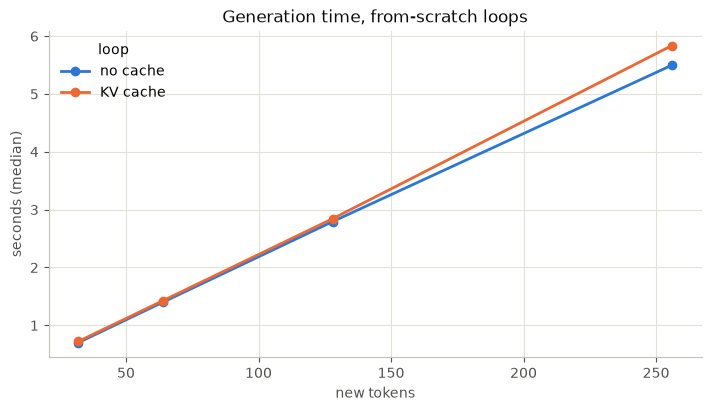

A1 KV cache, from scratch: seconds for 256 tokens 5.5 -> 5.84, 0.94x better


In [15]:
CACHE_SWEEP = (32, 64, 128, 256)  # output lengths to time, in new tokens
LOOPS = {"no cache": greedy_no_cache, "KV cache": greedy_with_cache}

rows = []
for n in CACHE_SWEEP:
    for name, loop in LOOPS.items():
        call = partial(loop, target, open_ids, n)
        seconds = time_calls(call, cfg.n_repeat_slow, n_warmup=0)  # warmed up above
        rows.append({"loop": name, "new tokens": n, "seconds": np.median(seconds)})
sweep = pd.DataFrame(rows).pivot(index="new tokens", columns="loop", values="seconds")
sweep = sweep[list(LOOPS)]  # columns in the order of LOOPS
display(sweep.round(2))

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
sweep.plot(ax=ax, marker="o", color=["#2a78d6", "#eb6834"])  # colorblind-checked
ax.set(xlabel="new tokens", ylabel="seconds (median)",
       title="Generation time, from-scratch loops")
plt.show()

n_max = CACHE_SWEEP[-1]
add_to_summary("1", "KV cache, from scratch", f"seconds for {n_max} tokens",
               sweep.loc[n_max, "no cache"], sweep.loc[n_max, "KV cache"],
               higher_is_better=False)

### Why KV cash did so bad: Python, not the GPU

On a fast GPU, both loops can be equally fast, and the cache can even be a bit slower.
One H100 run: 22 ms per token for both, ~10% of the speed limit. The GPU is mostly
waiting.

**Why**
- For every token, Python starts ~2,000 small GPU jobs (kernels), one after another.
- Starting one job takes the CPU ~10 microseconds: ~20 ms per token.
- Running all of them takes the GPU only ~3 ms.

So the CPU sets the speed, and the GPU sits idle between jobs:

    CPU: |--start job 1--|--start job 2--|--start job 3--|
    GPU:     [job 1]         [job 2]         [job 3]          idle in between

Extra GPU work is free as long as it fits in that idle time. With a short prompt, the
work the cache saves fits there, so the cache gains nothing. It even adds a few jobs
of its own.

**When the cache does help**
- With long prompts: then the work it saves is larger than the idle time. "Make it count"
  below shows this.
- On slower GPUs (T4, L4): there the GPU work itself takes longer than starting it.

A bigger model does not help: it slows both loops down by the same amount. Section 2
removes the start-up cost itself.


The same switch in `generate()`: `use_cache=False` against the default (KV cache on).

In [16]:
a1_runs = {
    "no cache": measure_generate(
        target, open_ids, n_repeat=cfg.n_repeat_slow, use_cache=False
    ),
    "KV cache (default)": measure_generate(target, open_ids),
}
display(speed_table(a1_runs))
add_runs_to_summary("1", a1_runs, ", generate()")

cached = np.median(a1_runs["KV cache (default)"].tok_s)
log.info(f"With KV cache: {cached:.0f} tok/s = {cached / SPEED_LIMIT:.0%} "
         f"of the speed limit ({SPEED_LIMIT:.0f} tok/s)")

,tok/s,tok/s 95% CI,speed-up,peak GB
config,,,,
no cache,42.10,42.1 - 42.3,1.00,8.10
KV cache (default),41.65,40.9 - 42.0,0.99,8.13


A1 KV cache (default), generate(): tok/s 42.1 -> 41.7, 0.99x better
With KV cache: 42 tok/s = 10% of the speed limit (416 tok/s)


### What the cache costs

For every token, every layer stores one key vector and one value vector per KV head:

    bytes per token = 2 x layers x KV heads x head dim x bytes per value

Qwen3 uses **grouped-query attention (GQA)**: several query heads share one KV head.
Qwen3-4B has 32 query heads and 8 KV heads, so its cache is 4x smaller than if every
query head had its own (multi-head attention).

For long contexts or many users at once, the cache, not the weights, fills the GPU.

In [ ]:
def kv_bytes_per_token(kv_heads: int) -> int:
    """KV cache bytes per token: one key and one value per layer and KV head."""
    return 2 * config.num_hidden_layers * kv_heads * HEAD_DIM * DTYPE.itemsize


per_token = kv_bytes_per_token(config.num_key_value_heads)  # GQA, as in Qwen3
per_token_mha = kv_bytes_per_token(config.num_attention_heads)  # one KV head per query
log.info(f"KV cache per token: {per_token / 1e3:.0f} KB "
         f"(without GQA: {per_token_mha / 1e3:.0f} KB)")

kv_table = pd.DataFrame([
    {
        "context tokens": context,
        "users (batch)": batch,
        "KV cache GB": per_token * context * batch / GB,
        "KV cache GB without GQA": per_token_mha * context * batch / GB,
        "weights GB": weight_bytes / GB,
    }
    for context in (4096, 32768)
    for batch in (1, 8)
])
display(kv_table.round(1))

KV cache per token: 147 KB (without GQA: 590 KB)


,context tokens,users (batch),KV cache GB,KV cache GB without GQA,weights GB
0,4096,1,0.6,2.4,8.0
1,4096,8,4.8,19.3,8.0
2,32768,1,4.8,19.3,8.0
3,32768,8,38.7,154.6,8.0


### KV cash for long prompts

On a fast GPU, the cache only pays off when it saves more GPU work than the ~20 ms of
Python overhead per token. That happens with long prompts. So this sweep changes the
**prompt length** (512 to 8,192 tokens) instead of the output length.

**What each timed call does**
- Generates 32 new tokens (`N_NEW_CONTEXT`), starting from scratch with a new cache.
- **Without cache**: every step reprocesses the whole prompt, so it gets slower as the
  prompt gets longer.
- **With cache**: only the first step reads the prompt; every later step processes
  1 token, so the speed stays about the same.

**The prompt**
- The open prompt, repeated until it reaches the target length.
- The model's answer is nonsense, and we ignore it. Only the length matters for the time.

**What we report**
- Milliseconds per new token: the median of 3 calls, divided by 32.

**What to expect**
- **No cache**: flat at ~20 ms for short prompts, then rising with the prompt length.
- **KV cache**: almost flat at every length.
- One H100 run: 21 vs 23 ms per token at 512 tokens, 197 vs 28 ms at 8,192 tokens (7x
  faster with the cache).


loop,no cache,KV cache
context tokens,,
512,20.9,22.5
1024,25.9,22.7
2048,46.1,23.0
4096,92.7,24.7
8192,196.7,28.1


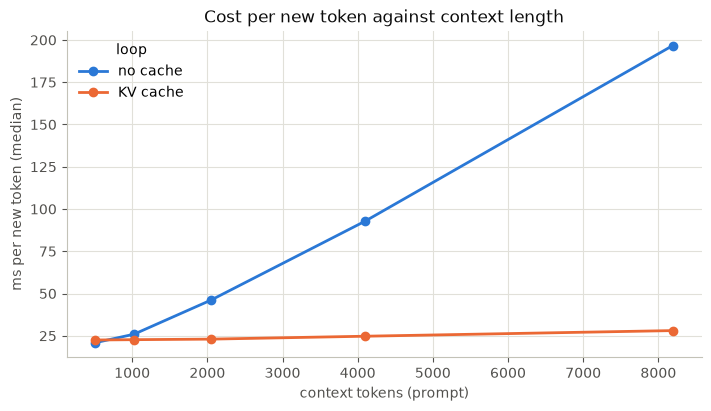

In [25]:
CONTEXT_SWEEP = (512, 1024, 2048, 4096, 8192)  # prompt lengths, in tokens
N_NEW_CONTEXT = 32  # new tokens per timed call


def context_ids(n_tokens: int) -> torch.Tensor:
    """Exactly n_tokens prompt ids: the open prompt repeated; only length matters."""
    n_copies = math.ceil(n_tokens / open_ids.shape[1])
    return open_ids.repeat(1, n_copies)[:, :n_tokens]


rows = []
for n_ctx in CONTEXT_SWEEP:
    ids = context_ids(n_ctx)
    for name, loop in LOOPS.items():
        call = partial(loop, target, ids, N_NEW_CONTEXT)
        seconds = time_calls(call, cfg.n_repeat_slow)  # 1 warm-up: new prompt length
        rows.append({
            "loop": name,
            "context tokens": n_ctx,
            "ms per new token": 1000 * np.median(seconds) / N_NEW_CONTEXT,
        })
ctx_sweep = pd.DataFrame(rows).pivot(
    index="context tokens", columns="loop", values="ms per new token"
)[list(LOOPS)]
display(ctx_sweep.round(1))

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ctx_sweep.plot(ax=ax, marker="o", color=["#2a78d6", "#eb6834"])  # colorblind-checked
ax.set(xlabel="context tokens (prompt)", ylabel="ms per new token (median)",
       title="Cost per new token against context length")
plt.show()

n_ctx_max = CONTEXT_SWEEP[-1]
add_to_summary("1", f"KV cache, {n_ctx_max}-token prompt", "ms per new token",
               ctx_sweep.loc[n_ctx_max, "no cache"],
               ctx_sweep.loc[n_ctx_max, "KV cache"],
               higher_is_better=False)

---

## 3. Static cache and `torch.compile`

At batch size 1, every decode step launches ~2,000 small GPU functions ("kernels"),
~55 per layer. Each one finishes quickly, so the time Python and the CUDA driver spend
*starting* them is a large part of the step; on a fast GPU, most of it (see "Where the
time goes" in the KV cache section).

`torch.compile` can merge kernels and record the whole step once as a **CUDA graph**,
then replay it with a single launch. That only works if tensor shapes never change. A
normal (dynamic) cache grows by one position per step, so its shape changes every step.
A **static cache** reserves space for the maximum length up front, so shapes stay fixed.

`transformers` compiles the decode step automatically with
`cache_implementation="static"`. `disable_compile=True` turns compilation off, so we can
separate the two effects:
1. dynamic cache (baseline)
2. static cache, no compile
3. static cache + compile

Compilation happens once per shape (prompt length + output length) and can take a minute
or more. We time it separately. A new prompt length means a new compilation, so this
pays off for servers with fixed shapes, not for one-off scripts.

In [ ]:
a2_runs = {
    "dynamic cache (baseline)": measure_generate(target, open_ids),
    "static cache, no compile": measure_generate(
        target, open_ids, cache_implementation="static", disable_compile=True
    ),
}

# The first call with compilation on traces and compiles the decode step: time it alone
try:
    first_call = partial(generate, target, open_ids, cache_implementation="static")
    compile_s = time_calls(first_call, n_repeat=1, n_warmup=0)[0]
    a2_runs["static cache + torch.compile"] = measure_generate(
        target, open_ids, n_warmup=2, cache_implementation="static"
    )
except Exception as err:  # compile support depends on GPU, driver and Triton version
    compile_s = math.nan
    log.warning(f"torch.compile failed, skipped: {type(err).__name__}: {err}")

display(speed_table(a2_runs))
add_runs_to_summary("2", a2_runs)

In [ ]:
if "static cache + torch.compile" in a2_runs:
    base = np.median(a2_runs["dynamic cache (baseline)"].tok_s)
    compiled = np.median(a2_runs["static cache + torch.compile"].tok_s)
    # First call = compilation + one normal generation
    one_off_s = compile_s - cfg.n_new_tokens / compiled
    log.info(f"Compilation: ~{one_off_s:.0f} s, once per prompt length + output length")
    if compiled > base:
        saved_per_token = 1 / base - 1 / compiled
        log.info(f"Pays off after ~{one_off_s / saved_per_token:,.0f} generated tokens "
                 "with the same shapes")

# Drop the compiled graphs and their memory before the next section
torch.compiler.reset()
free_memory()

# Summary

Every comparison above, against the baseline of its own section. "x better": 2 means
twice as fast or half the memory; below 1 means worse. The confidence intervals are in
each section's table.

In [ ]:
BETTER, WORSE = "#2a78d6", "#e34948"  # bars: blue = better, red = worse

summary = pd.DataFrame(SUMMARY)
display(summary.set_index(["section", "technique", "metric"]).round(3))

rows = summary.iloc[::-1]  # first comparison at the top of the chart
y = np.arange(len(rows))
x_better = rows["x better"].to_numpy()
fig, ax = plt.subplots(figsize=(10, 0.35 * len(rows) + 1.5), layout="constrained")
# Bars run from 1 (same as the baseline) to the measured factor. Log scale: 2x better
# and 2x worse get the same length
ax.barh(y, x_better - 1, left=1, height=0.6,
        color=np.where(x_better >= 1, BETTER, WORSE))
for yi, xb in zip(y, x_better):
    ax.annotate(f"{xb:.2f}x", (xb, yi), xytext=(4 if xb >= 1 else -4, 0),
                textcoords="offset points", ha="left" if xb >= 1 else "right",
                va="center", fontsize=8)
labels = rows["section"] + "  " + rows["technique"] + ": " + rows["metric"]
ax.set_yticks(y, labels, fontsize=8)
ax.set_xscale("log")
ax.axvline(1, color="#c3c2b7", linewidth=1)
ax.grid(axis="y", visible=False)
ax.margins(x=0.15)
ax.set(xlabel="x better than the section's baseline (log scale; below 1 = worse)",
       title="Every comparison against its own baseline")
plt.show()

What to look for. This is the expected pattern, not a result; your numbers are in the
table above.
- **1. KV cache**: the gain depends on how much work the cache saves per token, so on the
  prompt length and the GPU. With a short prompt on a fast GPU it can be ~1x, because
  Python overhead sets the speed. With a long prompt it is large, and it grows with the
  prompt length.
- **2. Static cache + compile**: compilation removes launch overhead, so it helps most
  where overhead is a big part of a step: small models and fast GPUs. The one-off
  compile time only pays off for fixed shapes and many tokens.

The KV cache is always on in practice. Static cache + compile is the next step when the
time goes to per-step overhead.

In [ ]:
free_memory()
log.info("Done. Colab: Runtime > Disconnect and delete runtime. "
         "VM: stop it in the console.")